# Preparación y verificación de los insumos

In [1]:
# =============================================================================
# D3 — Union del grafo (D2) con la pendiente (frente de terreno)
# Lee de disco, escribe en entregables/D3. No modifica nada de D2.
# =============================================================================
import json
import numpy as np
import pandas as pd
import geopandas as gpd

import constantes_d1 as K
import d1_grafo as d1
from d1_procedencia import huella_segmentos, sha256_archivo

# =============================================================================
# RAMA A EJECUTAR. Cambiar este nombre y correr el cuaderno completo otra vez
# para la otra rama. Cada rama escribe en su propia carpeta.
# =============================================================================
# Por defecto se ejecuta la rama OFICIAL (constantes_d1.RAMA_OFICIAL).
# Para regenerar la de sensibilidad, escribir aqui "sigma0538".
RAMA_NOMBRE = K.RAMA_OFICIAL or "sigma101"

RAMA = K.RAMAS_PENDIENTE[RAMA_NOMBRE]
ARCHIVO_PENDIENTE = RAMA["archivo"]
RUTA_PENDIENTE = K.ruta_cruda() / "recibidos" / ARCHIVO_PENDIENTE
CARPETA_SALIDA = f"D3/rama_{RAMA_NOMBRE}"

print(f"RAMA           : {RAMA_NOMBRE}  ({RAMA['descripcion']})")
print(f"sigma_z        : {RAMA['sigma_z_m']} m")
print(f"Oficial        : "
      f"{'SI' if K.RAMA_OFICIAL == RAMA_NOMBRE else 'pendiente de decision' if K.RAMA_OFICIAL is None else 'NO (sensibilidad)'}")
print()

# --- 1. El grafo es exactamente el que D2 registro ---------------------------
_hue_d2 = json.loads(K.ruta_entregable("D2", "D2_huellas_salidas.json")
                     .read_text(encoding="utf-8"))
seg = gpd.read_file(K.ruta_entregable("D2", "D2_segmentos_para_pendiente.gpkg"),
                    layer="segmentos")
seg["segmento_id"] = seg["segmento_id"].astype("string")
assert (huella_segmentos(seg)
        == _hue_d2["contenido"]["D2_segmentos_para_pendiente.gpkg"]), \
    "El GeoPackage de D2 no es el que D2 registro. Vuelva a correr D2."
print(f"Grafo D2: {len(seg):,} segmentos, huella verificada")

# --- 2. El archivo de pendiente existe; su hash queda registrado -------------
if not RUTA_PENDIENTE.exists():
    raise FileNotFoundError(
        f"Todavia no esta el archivo de pendiente:\n  {RUTA_PENDIENTE}\n"
        "Este cuaderno se ejecuta cuando el frente de pendiente entregue.")
SHA_PENDIENTE = sha256_archivo(RUTA_PENDIENTE)
pen = pd.read_csv(RUTA_PENDIENTE, dtype={"segmento_id": "string"},
                  encoding="utf-8")
print(f"Pendiente: {len(pen):,} filas  sha {SHA_PENDIENTE[:12]}...")

BITACORA = {"cuaderno": "D3 — union grafo + pendiente",
            "ejecucion_iniciada": d1.sello_de_tiempo(),
            "huella_segmentos_d2": huella_segmentos(seg),
            "archivo_pendiente": ARCHIVO_PENDIENTE,
            "sha256_pendiente": SHA_PENDIENTE,
            "rama": RAMA_NOMBRE,
            "rama_descripcion": RAMA["descripcion"],
            "sigma_z_rama": RAMA["sigma_z_m"],
            "ancho_correlacion_rama": RAMA["ancho_correlacion_m"],
            "rama_oficial_al_ejecutar": K.RAMA_OFICIAL}

RAMA           : sigma0536_v1_1  (Re-entrega de Danna (2026-10-13): sigma_z 0,536; solo cambian error, ruido acumulada y marca 2 sigma)
sigma_z        : 0.536 m
Oficial        : SI

Grafo D2: 225,704 segmentos, huella verificada
Pendiente: 225,704 filas  sha 445009d19b07...


# Las pruebas del contrato

In [2]:
# =============================================================================
# PRUEBAS DEL CONTRATO. Cada una recalcula por un camino independiente, con la
# geometria de D2, algo que el frente de pendiente calculo con la suya.
# =============================================================================
def _a_bool(s):
    """Normaliza booleanos leidos de CSV ('True'/'False'); lo demas -> NaN."""
    return s.map({True: True, False: False, "True": True, "False": False,
                  "true": True, "false": False})

pr = []

# 1. Estan todas las columnas del contrato
_faltan = [c for c in K.COLUMNAS_RETORNO_PENDIENTE if c not in pen.columns]
pr.append({"prueba": "columnas del contrato presentes",
           "faltan": _faltan, "pasa": not _faltan})
assert not _faltan, f"Faltan columnas del contrato: {_faltan}"

# 2. Los identificadores cruzan al 100 % en ambas direcciones, sin repetidos
_a, _b = set(seg["segmento_id"]), set(pen["segmento_id"])
pr.append({"prueba": "segmento_id: 100 % en ambas direcciones",
           "solo_en_grafo": len(_a - _b), "solo_en_pendiente": len(_b - _a),
           "repetidos_en_pendiente": int(pen["segmento_id"].duplicated().sum()),
           "pasa": _a == _b and pen["segmento_id"].is_unique})
assert _a == _b, ("Los IDs no cruzan: el archivo no se hizo sobre esta "
                  "exportacion de D2.")

m = seg[["segmento_id", "id_eje", "parte", "sentido_recorrido",
         "longitud_m"]].merge(pen, on="segmento_id", validate="one_to_one")
val = m["pendiente_neta_pct"].notna()

# 3. Pendientes coherentes con la LONGITUD DE D2 y en PORCENTAJE.
#    Si estuvieran en fraccion, o calculadas sobre otra geometria, no cuadran.
_neta = 100 * (m["z_fin_m"] - m["z_inicio_m"]) / m["longitud_m"]
_acum = (100 * (m["ganancia_elevacion_m"] + m["perdida_elevacion_m"])
         / m["longitud_m"])
_mal_neta = int((~np.isclose(m.loc[val, "pendiente_neta_pct"], _neta[val],
                             rtol=1e-6, atol=1e-6)).sum())
_mal_acum = int((~np.isclose(m["pendiente_acumulada_pct"], _acum,
                             rtol=1e-6, atol=1e-6, equal_nan=True)).sum())
pr.append({"prueba": "neta y acumulada = z y ganancia/perdida sobre longitud D2",
           "n_neta_distinta": _mal_neta, "n_acumulada_distinta": _mal_acum,
           "pasa": _mal_neta == 0 and _mal_acum == 0})

# 4. Signo: en cada eje de doble sentido, FT y TF son el mismo tramo recorrido
#    al reves. La neta cambia de signo y la ganancia de uno es la perdida del
#    otro.
_ft = m[m["sentido_recorrido"] == "FT"].set_index(["id_eje", "parte"])
_tf = m[m["sentido_recorrido"] == "TF"].set_index(["id_eje", "parte"])
_p = _ft.join(_tf, lsuffix="_ft", rsuffix="_tf", how="inner")
_ambos = (_p["pendiente_neta_pct_ft"].notna()
          & _p["pendiente_neta_pct_tf"].notna())
_mal_signo = int((~np.isclose(_p.loc[_ambos, "pendiente_neta_pct_ft"],
                              -_p.loc[_ambos, "pendiente_neta_pct_tf"],
                              atol=1e-6)).sum())
_mal_gan = int((~np.isclose(_p.loc[_ambos, "ganancia_elevacion_m_ft"],
                            _p.loc[_ambos, "perdida_elevacion_m_tf"],
                            atol=1e-3)).sum())
_nan_asim = int((_p["pendiente_neta_pct_ft"].isna()
                 != _p["pendiente_neta_pct_tf"].isna()).sum())
pr.append({"prueba": "FT y TF del mismo eje: signo y subida/bajada simetricos",
           "n_pares": int(len(_p)), "n_signo_mal": _mal_signo,
           "n_ganancia_perdida_mal": _mal_gan, "n_vacio_asimetrico": _nan_asim,
           "pasa": _mal_signo == 0 and _mal_gan == 0 and _nan_asim == 0})

# 5. Sin pendiente => sin clase, sin error, sin marca 2 sigma, y bandera de
#    cobertura. Con pendiente => sin bandera.
_sin = ~val
_fuera = _a_bool(m["fuera_cobertura_mdt"])
_dc = _a_bool(m["distinta_de_cero_2sigma"])
_incoh = int((_sin & (m["clasificacion_invias"].notna()
                      | m["error_pendiente_pct"].notna()
                      | _dc.notna())).sum())
pr.append({"prueba": "segmentos sin pendiente: coherentes y marcados",
           "n_sin_pendiente": int(_sin.sum()),
           "n_con_clase_o_error": _incoh,
           "n_sin_bandera": int((_sin & (_fuera != True)).sum()),
           "n_bandera_con_dato": int((val & (_fuera == True)).sum()),
           "pasa": (_incoh == 0 and int((_sin & (_fuera != True)).sum()) == 0
                    and int((val & (_fuera == True)).sum()) == 0)})

# 6. Clasificacion INVIAS recalculada desde la neta
_abs = m.loc[val, "pendiente_neta_pct"].abs()
_cls = np.select([_abs < 3, _abs < 6, _abs <= 8],
                 ["Plano", "Ondulado", "Montañoso"], "Escarpado")
_mal_cls = int((_cls != m.loc[val, "clasificacion_invias"].to_numpy()).sum())
pr.append({"prueba": "INVIAS = rangos oficiales sobre |neta|",
           "n_distinta": _mal_cls, "pasa": _mal_cls == 0})

# 7. sigma_z y ancho: un solo valor, y sigma_z y ancho iguales a los de la rama
_sz = m["sigma_z_m"].dropna().unique()
_an = m["ancho_correlacion_m"].dropna().unique()
_esp_sz, _esp_an = RAMA["sigma_z_m"], RAMA["ancho_correlacion_m"]
pr.append({"prueba": f"sigma_z y ancho unicos e iguales a los de la rama "
                     f"{RAMA_NOMBRE}",
           "sigma_z_en_archivo": [float(x) for x in _sz],
           "ancho_en_archivo": [float(x) for x in _an],
           "sigma_z_rama": _esp_sz, "ancho_rama": _esp_an,
           "pasa": (len(_sz) == 1 and len(_an) == 1
                    and bool(np.isclose(_sz[0], _esp_sz))
                    and bool(np.isclose(_an[0], _esp_an)))})

# 8. rho y error recalculados con la formula del contrato. Detecta que la
#    correccion de correlacion se aplico de verdad (rho no es 0 en todo) y
#    que el error usa la longitud de D2.
if len(_an) == 1 and len(_sz) == 1:
    _rho = np.exp(-m["longitud_m"] / _an[0])
    _err = 100 * np.sqrt(2 * _sz[0] ** 2 * (1 - _rho)) / m["longitud_m"]
    _mal_rho = int((~np.isclose(m.loc[val, "rho_correlacion"], _rho[val],
                                rtol=1e-6)).sum())
    _mal_err = int((~np.isclose(m.loc[val, "error_pendiente_pct"], _err[val],
                                rtol=1e-6)).sum())
else:
    _mal_rho = _mal_err = -1
pr.append({"prueba": "rho y error = formula del contrato",
           "n_rho_distinto": _mal_rho, "n_error_distinto": _mal_err,
           "pasa": _mal_rho == 0 and _mal_err == 0})

# 9. La marca 2 sigma se recalcula
_dc_calc = (m.loc[val, "pendiente_neta_pct"].abs()
            > 2 * m.loc[val, "error_pendiente_pct"])
_mal_dc = int((_dc_calc != _dc[val].astype(bool)).sum())
pr.append({"prueba": "distinta_de_cero_2sigma = |neta| > 2 * error",
           "n_distinta": _mal_dc, "pasa": _mal_dc == 0})

# 10. Piso de ruido de la acumulada, recalculado con la longitud de D2
if len(_an) == 1 and len(_sz) == 1:
    _k = m["n_puntos_muestreados"] - 1
    _ok = _k.gt(0) & m["ruido_acumulada_pct"].notna()
    _p_real = m["longitud_m"] / _k
    _sd = _sz[0] * np.sqrt(2 * (1 - np.exp(-_p_real / _an[0])))
    _ruido = 100 * np.sqrt(2 / np.pi) * _sd / _p_real
    _mal_ruido = int((~np.isclose(m.loc[_ok, "ruido_acumulada_pct"],
                                  _ruido[_ok], rtol=1e-6)).sum())
else:
    _mal_ruido = -1
pr.append({"prueba": "ruido_acumulada_pct = formula del contrato",
           "n_distinto": _mal_ruido, "pasa": _mal_ruido == 0})

# 11. pendiente_extrema recalculada con la cota fisica
_mx = np.fmax(m["pendiente_neta_pct"].abs(),
              m["pendiente_acumulada_pct"].abs())   # fmax ignora el vacio
_ext_calc = _mx > K.UMBRAL_PENDIENTE_EXTREMA_PCT
_ext = _a_bool(m["pendiente_extrema"])
_hay = _mx.notna()
_mal_ext = int((_ext_calc[_hay] != _ext[_hay].astype(bool)).sum())
pr.append({"prueba": "pendiente_extrema = max(|neta|,|acumulada|) > cota",
           "n_extremos": int(_ext_calc[_hay].sum()),
           "n_distinto": _mal_ext, "pasa": _mal_ext == 0})

RESUMEN = d1.resumen_pruebas(pr)
print(RESUMEN.to_string(index=False))
_fallan = [p["prueba"] for p in pr if not p["pasa"]]
BITACORA["pruebas"] = pr
assert not _fallan, f"NO se une. Fallan: {_fallan}"

                                                          prueba resultado                                                                                  detalle
                                 columnas del contrato presentes      PASA                                                                                faltan=[]
                         segmento_id: 100 % en ambas direcciones      PASA                           solo_en_grafo=0, solo_en_pendiente=0, repetidos_en_pendiente=0
       neta y acumulada = z y ganancia/perdida sobre longitud D2      PASA                                                n_neta_distinta=0, n_acumulada_distinta=0
         FT y TF del mismo eje: signo y subida/bajada simetricos      PASA             n_pares=95280, n_signo_mal=0, n_ganancia_perdida_mal=0, n_vacio_asimetrico=0
                  segmentos sin pendiente: coherentes y marcados      PASA       n_sin_pendiente=1374, n_con_clase_o_error=0, n_sin_bandera=0, n_bandera_con_dato=0
                

# La unión y las salidas

In [3]:
# =============================================================================
# UNION Y SALIDAS (solo se llega aqui si las 11 pruebas pasan)
# =============================================================================
union = (seg.merge(pen, on="segmento_id", validate="one_to_one")
         .sort_values("segmento_id").reset_index(drop=True))
union = gpd.GeoDataFrame(union, geometry="geometry", crs=seg.crs)

_n = f"_{RAMA_NOMBRE}"
sal_gpkg = K.ruta_entregable(CARPETA_SALIDA, f"D3_grafo_con_pendiente{_n}.gpkg")
sal_csv  = K.ruta_entregable(CARPETA_SALIDA, f"D3_grafo_con_pendiente{_n}.csv")
sal_hue  = K.ruta_entregable(CARPETA_SALIDA, f"D3_huellas_salidas{_n}.json")
sal_bit  = K.ruta_entregable(CARPETA_SALIDA, f"bitacora_ejecucion_D3{_n}.json")

if sal_gpkg.exists():
    sal_gpkg.unlink()
union.to_file(sal_gpkg, layer="grafo", driver="GPKG")
union.drop(columns="geometry").to_csv(sal_csv, index=False, encoding="utf-8")

_rel = gpd.read_file(sal_gpkg, layer="grafo")
assert huella_segmentos(_rel) == huella_segmentos(seg), \
    "La geometria del grafo unido no es la de D2"
assert len(_rel) == len(seg)

sal_hue.write_text(json.dumps({
    "archivos": {sal_csv.name: sha256_archivo(sal_csv)},
    "contenido": {sal_gpkg.name: huella_segmentos(union)},
    "rama": RAMA_NOMBRE,
    "sigma_z_m": RAMA["sigma_z_m"],
    "ancho_correlacion_m": RAMA["ancho_correlacion_m"],
    "insumos": {"huella_segmentos_d2": huella_segmentos(seg),
                "archivo_pendiente": ARCHIVO_PENDIENTE,
                "sha256_pendiente": SHA_PENDIENTE},
}, indent=2, ensure_ascii=False), encoding="utf-8")

BITACORA["ejecucion_terminada"] = d1.sello_de_tiempo()
sal_bit.write_text(json.dumps(BITACORA, indent=2, ensure_ascii=False,
                              default=str), encoding="utf-8")

print(f"Grafo con pendiente: {len(union):,} segmentos")
print(f"  sin pendiente (fuera de cobertura): "
      f"{int(union['pendiente_neta_pct'].isna().sum()):,}")
for p in (sal_gpkg, sal_csv, sal_hue, sal_bit):
    print(f"  {p.name:<34} {p.stat().st_size/1e6:>8.2f} MB")

Grafo con pendiente: 225,704 segmentos
  sin pendiente (fuera de cobertura): 1,374
  D3_grafo_con_pendiente_sigma0536_v1_1.gpkg   100.06 MB
  D3_grafo_con_pendiente_sigma0536_v1_1.csv    75.31 MB
  D3_huellas_salidas_sigma0536_v1_1.json     0.00 MB
  bitacora_ejecucion_D3_sigma0536_v1_1.json     0.00 MB


In [4]:
# =============================================================================
# COMPARACION ENTRE RAMAS (correr despues de ejecutar las dos)
# Deben ser identicas en todo salvo el error y la marca de 2 sigma.
# =============================================================================
_r = {}
for _nom in K.RAMAS_PENDIENTE:
    _ruta = K.ruta_entregable(f"D3/rama_{_nom}",
                              f"D3_grafo_con_pendiente_{_nom}.csv")
    assert _ruta.exists(), f"Falta ejecutar la rama {_nom}"
    _r[_nom] = (pd.read_csv(_ruta, dtype={"segmento_id": "string"})
                .set_index("segmento_id").sort_index())

_a, _b = _r["sigma0538"], _r["sigma101"]
assert _a.index.equals(_b.index), "Las ramas no tienen los mismos segmentos"

_iguales = ["pendiente_neta_pct", "pendiente_acumulada_pct",
            "ganancia_elevacion_m", "perdida_elevacion_m",
            "z_inicio_m", "z_fin_m", "clasificacion_invias",
            "pendiente_extrema", "fuera_cobertura_mdt", "longitud_m"]
print("Columnas que deben ser IDENTICAS entre ramas:")
for _c in _iguales:
    _ok = _a[_c].equals(_b[_c]) or np.allclose(
        pd.to_numeric(_a[_c], errors="coerce").fillna(-9999),
        pd.to_numeric(_b[_c], errors="coerce").fillna(-9999))
    print(f"  {_c:<26} {'identica' if _ok else 'DISTINTA'}")
    assert _ok, f"{_c} difiere entre ramas: no deberia"

print("\nLo unico que cambia entre ramas:")
_tabla = pd.DataFrame({
    _nom: {
        "sigma_z (m)": K.RAMAS_PENDIENTE[_nom]["sigma_z_m"],
        "tramos con pendiente": int(_r[_nom]["pendiente_neta_pct"].notna().sum()),
        "distinta de cero (2 sigma)": int((_r[_nom]["distinta_de_cero_2sigma"]
                                           .astype(str) == "True").sum()),
        "error mediano (%)": round(_r[_nom]["error_pendiente_pct"].median(), 2),
    } for _nom in _r})
_tabla.loc["% distinta de cero"] = (
    100 * _tabla.loc["distinta de cero (2 sigma)"]
    / len(_a)).round(1)
print(_tabla.to_string())
print(f"\nRama oficial: {K.RAMA_OFICIAL or 'pendiente de decision de la tutoria'}")

C:\Users\junio\AppData\Local\Temp\ipykernel_9508\1589625666.py:10: DtypeWarning: Columns (0: distinta_de_cero_2sigma, 1: pendiente_extrema) have mixed types. Specify dtype option on import or set low_memory=False.
  _r[_nom] = (pd.read_csv(_ruta, dtype={"segmento_id": "string"})
C:\Users\junio\AppData\Local\Temp\ipykernel_9508\1589625666.py:10: DtypeWarning: Columns (0: distinta_de_cero_2sigma, 1: pendiente_extrema) have mixed types. Specify dtype option on import or set low_memory=False.
  _r[_nom] = (pd.read_csv(_ruta, dtype={"segmento_id": "string"})


Columnas que deben ser IDENTICAS entre ramas:
  pendiente_neta_pct         identica
  pendiente_acumulada_pct    identica
  ganancia_elevacion_m       identica
  perdida_elevacion_m        identica
  z_inicio_m                 identica
  z_fin_m                    identica
  clasificacion_invias       identica
  pendiente_extrema          identica
  fuera_cobertura_mdt        identica
  longitud_m                 identica

Lo unico que cambia entre ramas:
                             sigma0538   sigma101  sigma0533_v1  sigma0536_v1_1
sigma_z (m)                      0.538       1.01         0.533           0.536
tramos con pendiente        221734.000  221734.00    224330.000      224330.000
distinta de cero (2 sigma)   73880.000   57064.00     70425.000       70263.000
error mediano (%)                1.000       1.88         1.210           1.210
% distinta de cero              32.700      25.30        31.200          31.100

Rama oficial: sigma0536_v1_1


Distinguibles con ambas ramas : 57,064
Solo con sigma 0,538 (cambian): 16,816
Con ninguna                   : 147,854
Solo con sigma 1,01 (debe ser 0): 0

Perfil de cada grupo:
                         ambas ramas  solo 0,538   ninguna
tramos                       57064.0     16816.0  147854.0
longitud mediana (m)            45.2        47.4      49.1
|pendiente| mediana (%)         11.0         2.7       0.4

Los que cambian, por clasificacion INVIAS:
invias
Plano        9742
Ondulado     6287
Montañoso     604
Escarpado     183

Los que cambian, por clase de via (y % de su clase):
             cambian   total  pct
highway                          
sin_definir     1112   11438  9.7
intermedia      3616   46695  7.7
arterial        1345   17687  7.6
local          10414  143606  7.3
rural            329    6278  5.2

Los que cambian, por localidad (10 primeras):
localidad
CIUDAD BOLIVAR        3072
USME                  2343
RAFAEL URIBE URIBE    1699
SAN CRISTOBAL         1513
SUBA   

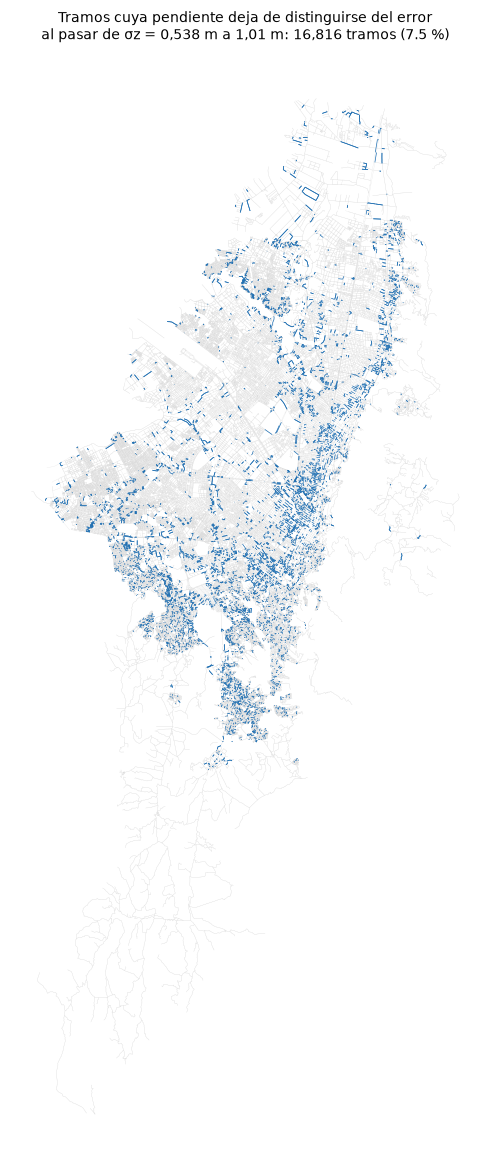

Figura: F:\Tesis\Grafo Bogotá\entregables\D3\D3_tramos_que_cambian_entre_ramas.png


In [5]:
# =============================================================================
# QUE TRAMOS CAMBIAN ENTRE RAMAS
# Tramos con pendiente distinguible del error con sigma_z = 0,538 pero NO con
# 1,01. Las pendientes son identicas en ambas ramas: solo cambia la confianza.
# =============================================================================
import matplotlib.pyplot as plt

def _dc(df):
    return df["distinta_de_cero_2sigma"].astype(str) == "True"

_seg = gpd.read_file(K.ruta_entregable("D2", "D2_segmentos_para_pendiente.gpkg"),
                     layer="segmentos")
_seg["segmento_id"] = _seg["segmento_id"].astype("string")
_seg = _seg.set_index("segmento_id").sort_index()

_cmp = _seg[["localidad", "highway", "longitud_m", "geometry"]].join(
    pd.DataFrame({"neta": _a["pendiente_neta_pct"],
                  "invias": _a["clasificacion_invias"],
                  "dc_0538": _dc(_a), "dc_101": _dc(_b)}))

_cambia = _cmp["dc_0538"] & ~_cmp["dc_101"]
_nunca = ~_cmp["dc_0538"] & _cmp["neta"].notna()
_siempre = _cmp["dc_101"]
_inverso = _cmp["dc_101"] & ~_cmp["dc_0538"]

print(f"Distinguibles con ambas ramas : {int(_siempre.sum()):,}")
print(f"Solo con sigma 0,538 (cambian): {int(_cambia.sum()):,}")
print(f"Con ninguna                   : {int(_nunca.sum()):,}")
print(f"Solo con sigma 1,01 (debe ser 0): {int(_inverso.sum()):,}")
assert _inverso.sum() == 0, "Un sigma mayor nunca puede ganar tramos"

def _perfil(mascara, nombre):
    s = _cmp[mascara]
    return pd.Series({
        "tramos": len(s),
        "longitud mediana (m)": round(s["longitud_m"].median(), 1),
        "|pendiente| mediana (%)": round(s["neta"].abs().median(), 1),
    }, name=nombre)

print("\nPerfil de cada grupo:")
print(pd.concat([_perfil(_siempre, "ambas ramas"),
                 _perfil(_cambia, "solo 0,538"),
                 _perfil(_nunca, "ninguna")], axis=1).to_string())

print("\nLos que cambian, por clasificacion INVIAS:")
print(_cmp.loc[_cambia, "invias"].value_counts().to_string())

print("\nLos que cambian, por clase de via (y % de su clase):")
_t = pd.DataFrame({"cambian": _cmp.loc[_cambia, "highway"].value_counts(),
                   "total": _cmp["highway"].value_counts()})
_t["pct"] = (100 * _t["cambian"] / _t["total"]).round(1)
print(_t.sort_values("pct", ascending=False).to_string())

print("\nLos que cambian, por localidad (10 primeras):")
print(_cmp.loc[_cambia, "localidad"].value_counts().head(10).to_string())

# --- Mapa -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 12))
_cmp[~_cambia].plot(ax=ax, color="#DDDDDD", linewidth=0.15)
_cmp[_cambia].plot(ax=ax, color="#1F6FB2", linewidth=0.5)
ax.set_title("Tramos cuya pendiente deja de distinguirse del error\n"
             f"al pasar de σz = 0,538 m a 1,01 m: {int(_cambia.sum()):,} tramos "
             f"({100*_cambia.mean():.1f} %)", fontsize=10)
ax.set_axis_off()
plt.tight_layout()
_fig = K.ruta_entregable("D3", "D3_tramos_que_cambian_entre_ramas.png")
plt.savefig(_fig, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figura: {_fig}")

In [6]:
# =============================================================================
# CUANTAS CALLES SUBEN O BAJAN CON SEGURIDAD, SEGUN EL SIGMA_Z
# Lee las dos ramas ya escritas en entregables/D3. No recalcula pendientes:
# usa la marca distinta_de_cero_2sigma que viene del frente de pendiente,
# ya verificada por las 11 pruebas del contrato.
# =============================================================================
import pandas as pd
import constantes_d1 as K

resultados = {}
for rama, cfg in K.RAMAS_PENDIENTE.items():
    ruta = K.ruta_entregable(f"D3/rama_{rama}",
                             f"D3_grafo_con_pendiente_{rama}.csv")
    assert ruta.exists(), f"Falta ejecutar la rama {rama}"
    df = pd.read_csv(ruta, dtype={"segmento_id": "string", "id_eje": "string",
                                  "distinta_de_cero_2sigma": "string"},
                     usecols=["segmento_id", "id_eje", "parte",
                              "pendiente_neta_pct", "distinta_de_cero_2sigma"],
                     low_memory=False)

    con_dato = df["pendiente_neta_pct"].notna()
    segura = df["distinta_de_cero_2sigma"].astype(str) == "True"

    # --- Por sentido de recorrido (cada direccion cuenta aparte) -----------
    sube = segura & (df["pendiente_neta_pct"] > 0)
    baja = segura & (df["pendiente_neta_pct"] < 0)
    plana = con_dato & ~segura
    assert (sube | baja | plana).sum() == con_dato.sum(), \
        "Los tres grupos deben sumar el total de tramos con pendiente"

    # --- Por calle fisica (cada eje y parte cuenta una sola vez) -----------
    df["_segura"], df["_dato"] = segura, con_dato
    calles = df.groupby(["id_eje", "parte"]).agg(
        segura=("_segura", "any"), dato=("_dato", "any"),
        sentidos_distintos=("_segura", "nunique"))

    # Verificacion: en una calle de doble sentido, las dos direcciones tienen
    # la misma |pendiente| y el mismo error, asi que deben coincidir en la
    # marca. Si no, algo esta mal en el archivo.
    assert (calles["sentidos_distintos"] == 1).all(), \
        "Hay calles donde un sentido es seguro y el otro no"

    n_calles = int(calles["dato"].sum())
    n_seg = int((calles["segura"] & calles["dato"]).sum())

    resultados[rama] = {
        "sigma_z (m)": cfg["sigma_z_m"],
        "CALLES con pendiente medida": n_calles,
        "calles que suben o bajan con seguridad": n_seg,
        "% calles seguras": round(100 * n_seg / n_calles, 1),
        "calles que no se distinguen de plana": n_calles - n_seg,
        "% calles no distinguibles": round(100 * (n_calles - n_seg) / n_calles, 1),
        "TRAMOS con pendiente (por sentido)": int(con_dato.sum()),
        "tramos que suben con seguridad": int(sube.sum()),
        "tramos que bajan con seguridad": int(baja.sum()),
        "tramos que no se distinguen de plano": int(plana.sum()),
    }
    resultados[rama]["_calles_seguras_ids"] = set(
        calles.index[calles["segura"] & calles["dato"]])

# --- Tabla final -------------------------------------------------------------
tabla = pd.DataFrame({r: {k: v for k, v in d.items() if not k.startswith("_")}
                      for r, d in resultados.items()})
tabla["diferencia"] = tabla["sigma0538"] - tabla["sigma101"]
tabla.loc["sigma_z (m)", "diferencia"] = None
print(tabla.to_string())

# --- Verificacion: un error mayor nunca puede ganar calles seguras -----------
_a = resultados["sigma0538"]["_calles_seguras_ids"]
_b = resultados["sigma101"]["_calles_seguras_ids"]
print(f"\nCalles seguras con 1,01 que NO lo son con 0,538 (debe ser 0): "
      f"{len(_b - _a)}")
assert not (_b - _a), "Un sigma mayor no puede hacer seguras mas calles"
print(f"Calles que dejan de ser seguras al pasar a 1,01: {len(_a - _b):,}")

                                         sigma0538   sigma101  sigma0533_v1  sigma0536_v1_1  diferencia
sigma_z (m)                                  0.538       1.01         0.533           0.536         NaN
CALLES con pendiente medida             128341.000  128341.00    129730.000      129730.000         0.0
calles que suben o bajan con seguridad   39931.000   30092.00     37808.000       37711.000      9839.0
% calles seguras                            31.100      23.40        29.100          29.100         7.7
calles que no se distinguen de plana     88410.000   98249.00     91922.000       92019.000     -9839.0
% calles no distinguibles                   68.900      76.60        70.900          70.900        -7.7
TRAMOS con pendiente (por sentido)      221734.000  221734.00    224330.000      224330.000         0.0
tramos que suben con seguridad           36975.000   28528.00     35249.000       35167.000      8447.0
tramos que bajan con seguridad           36905.000   28536.00   

In [ ]:
# =============================================================================
# RAMA NUEVA (sigma0533_v1) vs SEPTIEMBRE (sigma101)
# Mismas elevaciones del mismo MDT, asi que donde ya habia dato la
# pendiente NO cambia; solo cambia la incertidumbre. Se recuperan 2.596 tramos.
# Esta celda lo comprueba. Solo lee; no escribe nada.
# =============================================================================
_lee = lambda nom: (pd.read_csv(
    K.ruta_entregable(f"D3/rama_{nom}", f"D3_grafo_con_pendiente_{nom}.csv"),
    dtype={"segmento_id": "string", "distinta_de_cero_2sigma": "string",
           "pendiente_extrema": "string"}, low_memory=False)
    .set_index("segmento_id").sort_index())
_v, _n = _lee("sigma101"), _lee("sigma0533_v1")
assert _v.index.equals(_n.index), "Las ramas no tienen los mismos segmentos"

_dv = _v["pendiente_neta_pct"].notna()
_dn = _n["pendiente_neta_pct"].notna()
pr_v1 = []

# 1. Nadie pierde dato: todo lo que tenia pendiente en septiembre la sigue teniendo
pr_v1.append(("ningun tramo pierde su pendiente", int((_dv & ~_dn).sum()) == 0))

# 2. Donde ya habia dato, pendiente, alturas, clase y marca extrema IDENTICAS
_num = ["pendiente_neta_pct", "pendiente_acumulada_pct", "ganancia_elevacion_m",
        "perdida_elevacion_m", "z_inicio_m", "z_fin_m"]
for c in _num:
    _dif = (_v.loc[_dv, c] - _n.loc[_dv, c]).abs().max()
    pr_v1.append((f"{c} identica donde ya habia dato (dif max {_dif:.2e})",
                  bool(_dif < 1e-9)))
for c in ["clasificacion_invias", "pendiente_extrema"]:
    _ndif = int((_v.loc[_dv, c] != _n.loc[_dv, c]).sum())
    pr_v1.append((f"{c} identica donde ya habia dato ({_ndif} distintas)", _ndif == 0))

# 3. Recuperados = 2.596; quedan 1.374 sin dato
_rec = _dn & ~_dv
pr_v1.append((f"tramos recuperados = 2.596 ({int(_rec.sum()):,})", int(_rec.sum()) == 2596))
pr_v1.append((f"siguen sin dato = 1.374 ({int((~_dn).sum()):,})", int((~_dn).sum()) == 1374))

# 4. Extremas nuevas: todas salen de los recuperados (40 filas, 20 tramos)
# .fillna(False): en los recuperados septiembre esta vacio; un vacio NO es extrema
# (sin esto, "vacio == True" da <NA> y la suma lo ignora)
_ext_v = _v["pendiente_extrema"].eq("True").fillna(False).astype(bool)
_ext_n = _n["pendiente_extrema"].eq("True").fillna(False).astype(bool)
_nuevas = _ext_n & ~_ext_v
pr_v1.append((f"extremas nuevas = 40 ({int(_nuevas.sum())})", int(_nuevas.sum()) == 40))
pr_v1.append(("todas las extremas nuevas son tramos recuperados",
              bool((_nuevas <= _rec).all())))

# 5. Recuperados: FT y TF juntos (no se recupera solo un sentido)
_e = _n.loc[_rec].reset_index()
_e["calle"] = _e["segmento_id"].str.rsplit("_", n=1).str[0]
_lado = _n.reset_index()
_lado["calle"] = _lado["segmento_id"].str.rsplit("_", n=1).str[0]
_lado = _lado[_lado["calle"].isin(set(_e["calle"]))]
pr_v1.append(("en las calles recuperadas, todos sus sentidos tienen dato",
              bool(_lado["pendiente_neta_pct"].notna().all())))

_df = pd.DataFrame(pr_v1, columns=["prueba", "pasa"])
_df["resultado"] = np.where(_df["pasa"], "PASA", "FALLA")
print("RAMA NUEVA vs SEPTIEMBRE")
print(_df[["prueba", "resultado"]].to_string(index=False))
assert _df["pasa"].all(), f"Fallan: {_df.loc[~_df['pasa'], 'prueba'].tolist()}"

print(f"\nTramos recuperados por localidad (10 primeras):")
print(_n.loc[_rec, "localidad"].value_counts().head(10).to_string())
print(f"\nExtremas nuevas: {int(_nuevas.sum())} filas, "
      f"|pendiente| max {_n.loc[_nuevas, 'pendiente_neta_pct'].abs().max():.1f} %")
print(f"Calles fisicas recuperadas: {_e['calle'].nunique():,}")

RAMA NUEVA vs SEPTIEMBRE
                                                                 prueba resultado
                                       ningun tramo pierde su pendiente      PASA
     pendiente_neta_pct identica donde ya habia dato (dif max 2.84e-14)      PASA
pendiente_acumulada_pct identica donde ya habia dato (dif max 2.84e-14)      PASA
   ganancia_elevacion_m identica donde ya habia dato (dif max 0.00e+00)      PASA
    perdida_elevacion_m identica donde ya habia dato (dif max 0.00e+00)      PASA
             z_inicio_m identica donde ya habia dato (dif max 0.00e+00)      PASA
                z_fin_m identica donde ya habia dato (dif max 0.00e+00)      PASA
        clasificacion_invias identica donde ya habia dato (0 distintas)      PASA
           pendiente_extrema identica donde ya habia dato (0 distintas)      PASA
                                     tramos recuperados = 2.596 (2,596)      PASA
                                        siguen sin dato = 1.374 (1,374)  

## Rama oficial nueva: archivo final de pendientes (sigma0533_v1)

Danna entregó el archivo final de pendientes (`bogota_pendientes_segmentos_mdt2020_v1.csv`,
sha256 `796efe21…`), que reemplaza al de septiembre. Cambian tres cosas:

- **σz de 1,01 a 0,533 m.** Revisó los vértices del IGAC con el criterio de la ASPRS y
  excluyó solo los que tenían evidencia de problema en el vértice: 5 destruidos, 1-CM-5
  (marca en un patio elevado) y 10-E-1 (−7,5 m en el MDT 2020 y en el 2025). Quedan 77.
- **Ancho de correlación de 94,5 a 53,6 m.** Corrige un error de lectura: el 94,5 era el
  rango del modelo gaussiano. El rango exponencial es 160,9 m y A = 160,9 / 3.
- **2.596 tramos recuperados**, que antes salían vacíos por un defecto en la consulta
  por lotes al MDT.

**Comprobado por un segundo camino** (celda de comparación, 14 pruebas): donde ya había
dato, pendiente, alturas, clase INVIAS y marca de extrema son idénticas a septiembre.
Solo cambia la incertidumbre. Se recuperan 2.596 tramos (1.389 calles), siguen 1.374
sin dato y aparecen 40 extremas nuevas, todas entre los recuperados (máx. 57,6 %).

Resultado: tramos que suben o bajan con seguridad, 31,2 % (septiembre 25,3 %).
Las ramas sigma101 y sigma0538 se conservan como sensibilidad.